# 05 · Análisis I (zoom): super-Tierras y sub-Neptunos

**Pregunta.** Entre los planetas de 1 a 4 R terrestres, ¿cómo se relaciona la probabilidad de ser sub-Neptuno con el flujo incidente y con las propiedades de la estrella? ¿Depende el efecto del flujo de la masa estelar?

**Clasificación conservadora.** Super-Tierra: $1 < R_p < 1.6\,R_\oplus$; sub-Neptuno: $2.0 < R_p < 4\,R_\oplus$. El intervalo $1.6$–$2.0\,R_\oplus$, cercano al radius valley, se excluye (pirque no se pueden clasificar con seguridad como super tierras o subneptunos)

**Muestra principal.** Planetas descubiertos por tránsito (radios medidos). La muestra con todos los métodos y la de Kepler (muestra mas homogenea) se usan como verificación


**Modelos** (regresión logística binaria; predictores centrados):

| Modelo | Predictores |
|---|---|
| M0 (base) | `logF_c` |
| M1 | `logF_c + Mstar_c + FeH_c` |
| M2 (estelar) | `logF_c + Mstar_c + FeH_c + logF_c_x_Mstar_c` |

**Salidas:** tablas Z-T1 a Z-T13; figuras Z-F1 a Z-F3.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from funciones import *

usar_estilo()

## 1. Muestras de planetas pequeños

In [7]:
df = cargar_catalogo()
pequenos = planetas_pequenos(df)
RESPUESTA = "sub_neptune_conservador"
PRED_M0 = ["logF_c"]
PRED_M1 = ["logF_c", "Mstar_c", "FeH_c"]
PRED_M2 = ["logF_c", "Mstar_c", "FeH_c", "logF_c_x_Mstar_c"]

filas = []
for muestra in ["transito", "completa", "kepler"]:
    d = pequenos[pequenos[f"muestra_{muestra}"]]
    m = muestra_zoom(pequenos, muestra)
    filas.append({"muestra": ETIQUETA_MUESTRA[muestra], "N_planetas": len(d), "N_estrellas": d["hostname"].nunique(),
                  "N_super_tierra": int((d["regimen_planetario"] == "super_tierra").sum()),
                  "N_valle_excluido": int((d["regimen_planetario"] == "valle_excluido").sum()),
                  "N_sub_neptuno": int((d["regimen_planetario"] == "sub_neptuno").sum()),
                  "N_modelo": len(m), "N_estrellas_modelo": m["hostname"].nunique(),
                  "fraccion_sub_neptuno_modelo": m[RESPUESTA].mean()})
tabla_muestras = guardar_tabla(
    pd.DataFrame(filas), "Z-T1", "muestras_planetas_pequenos",
    titulo="Planetas de 1 a 4 R_Tierra: muestra principal (tránsito) y muestras de robustez.",
    seccion="6.2.2",
    nota="N modelo: planetas clasificados (fuera del intervalo 1.6-2.0 R_Tierra) con flujo incidente, masa estelar y metalicidad.",
    encabezados={"N_super_tierra": "Super-Tierras", "N_valle_excluido": "Excluidos", "N_sub_neptuno": "Sub-Neptunos",
                 "N_modelo": r"$N$ modelo", "N_estrellas_modelo": r"$N_\star$ modelo",
                 "fraccion_sub_neptuno_modelo": "Fracción SN"})
tabla_muestras

Tabla Z-T1 guardada: tablas/Z-T1_muestras_planetas_pequenos.csv


,muestra,N_planetas,N_estrellas,N_super_tierra,N_valle_excluido,N_sub_neptuno,N_modelo,N_estrellas_modelo,fraccion_sub_neptuno_modelo
0,Tránsito,3261,2423,873,568,1820,2565,1981,0.6694
1,Todos los métodos,3592,2621,934,613,2045,2775,2097,0.6778
2,Kepler,2300,1694,659,424,1217,1876,1455,0.6487


Muestra principal: 2565 planetas, 1981 estrellas; fracción de sub-Neptunos = 0.669
Figura Z-F1 guardada: figuras/Z-F1_distribucion_radios_planetas_pequenos.png y .pdf


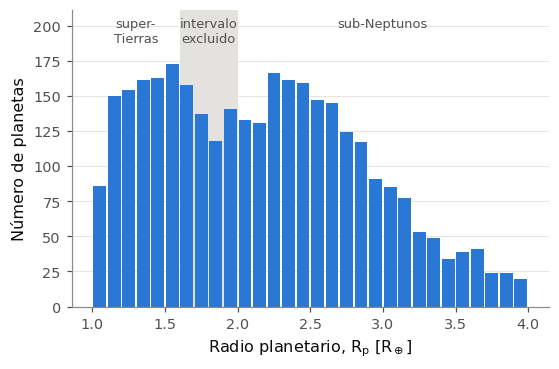

In [8]:
z = muestra_zoom(pequenos, "transito")
grupos = z["hostname"]
print(f"Muestra principal: {len(z)} planetas, {grupos.nunique()} estrellas; fracción de sub-Neptunos = {z[RESPUESTA].mean():.3f}")

d = pequenos[pequenos["muestra_transito"]]
fig, ax = plt.subplots(figsize=(5.6, 3.5))
ax.axvspan(R_VALLE_MIN, R_VALLE_MAX, color=GRIS_CLARO, zorder=0)
cuentas, _, _ = ax.hist(d["pl_rade"], bins=np.arange(1.0, 4.01, 0.1), color=COLOR_UNICO, rwidth=0.88)
ax.set_ylim(0, cuentas.max() * 1.22)
for x, texto in [(1.3, "super-\nTierras"), (1.8, "intervalo\nexcluido"), (3.0, "sub-Neptunos")]:
    ax.text(x, cuentas.max() * 1.19, texto, ha="center", va="top", fontsize=8.5, color=TINTA_SECUNDARIA)
ax.set_xlabel(EJE["pl_rade"])
ax.set_ylabel("Número de planetas")
ax.grid(axis="x", visible=False)
guardar_figura(fig, "Z-F1", "distribucion_radios_planetas_pequenos",
               titulo=("Distribución de radios de los planetas en tránsito entre 1 y 4 R_Tierra y clasificación conservadora: "
                       "super-Tierras (1-1.6 R_Tierra), intervalo excluido (1.6-2.0 R_Tierra) y sub-Neptunos (2-4 R_Tierra)."),
               seccion="6.2.2", nota=f"N = {len(d)} planetas.")
plt.show()

## 2. Descripción: fracción de sub-Neptunos por flujo incidente y por masa estelar

Fracciones observadas en cuartiles de flujo y terciles de masa estelar, con intervalos de Wilson al 95 %.

In [9]:
z["cuartil_logF"] = pd.qcut(z["log_insol_calculada"], 4, labels=["C1 (bajo)", "C2", "C3", "C4 (alto)"])
z["tercil_st_mass"] = pd.qcut(z["st_mass"], 3, labels=["T1 (baja)", "T2", "T3 (alta)"])

partes = []
for variable, grupo in [("log_insol_calculada", "cuartil_logF"), ("st_mass", "tercil_st_mass")]:
    t = fraccion_por_grupo(z, grupo, RESPUESTA).rename(columns={grupo: "grupo", "N_positivos": "N_sub_neptuno"})
    limites = z.groupby(grupo, observed=True)[variable].agg(["min", "median", "max"]).reset_index(drop=True)
    t.insert(0, "variable", variable)
    t.insert(2, "minimo", limites["min"])
    t.insert(3, "mediana", limites["median"])
    t.insert(4, "maximo", limites["max"])
    partes.append(t)
fracciones = pd.concat(partes, ignore_index=True)
tabla_fracciones = guardar_tabla(
    fracciones, "Z-T2", "fraccion_sub_neptunos_por_flujo_y_masa_estelar",
    titulo="Fracción observada de sub-Neptunos por cuartil de flujo incidente y por tercil de masa estelar, con intervalo de Wilson al 95 %.",
    seccion="6.2.2", decimales=3, encabezados={"grupo": "Grupo", "N_sub_neptuno": "Sub-Neptunos"})
tabla_fracciones

Tabla Z-T2 guardada: tablas/Z-T2_fraccion_sub_neptunos_por_flujo_y_masa_estelar.csv


,variable,grupo,minimo,mediana,maximo,N,N_sub_neptuno,fraccion,IC95_inf,IC95_sup
0,log_insol_calculada,C1 (bajo),-0.845,0.933,1.308,642,511,0.796,0.763,0.825
1,log_insol_calculada,C2,1.309,1.604,1.850,641,507,0.791,0.758,0.821
2,log_insol_calculada,C3,1.851,2.096,2.345,641,421,0.657,0.619,0.693
3,log_insol_calculada,C4 (alto),2.345,2.642,4.100,641,278,0.434,0.396,0.472
4,st_mass,T1 (baja),0.090,0.730,0.840,855,492,0.575,0.542,0.608
5,st_mass,T2,0.841,0.920,0.990,862,619,0.718,0.687,0.747
6,st_mass,T3 (alta),0.990,1.087,2.018,848,606,0.715,0.683,0.744


Figura Z-F2 guardada: figuras/Z-F2_fraccion_sub_neptunos_por_flujo_y_masa_estelar.png y .pdf


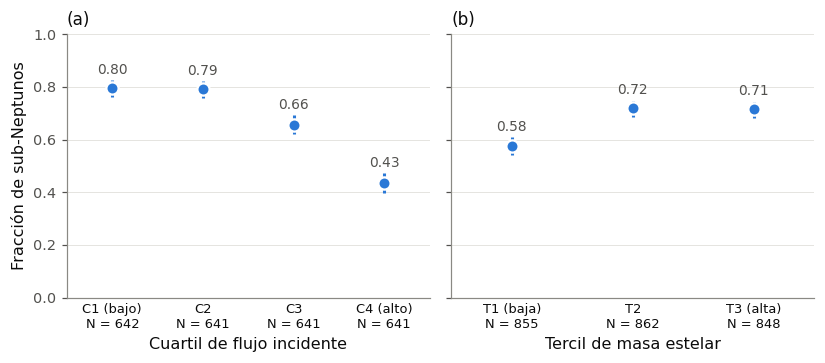

In [10]:
fig, ejes = plt.subplots(1, 2, figsize=(7.6, 3.4), sharey=True)
for ax, variable, etiqueta, letra in [(ejes[0], "log_insol_calculada", "Cuartil de flujo incidente", "a"),
                                      (ejes[1], "st_mass", "Tercil de masa estelar", "b")]:
    t = fracciones[fracciones["variable"] == variable]
    x = np.arange(len(t))
    ax.vlines(x, t["IC95_inf"], t["IC95_sup"], color=COLOR_UNICO, linewidth=2)
    ax.plot(x, t["fraccion"], "o", color=COLOR_UNICO, markersize=8, markeredgecolor="white", markeredgewidth=1.5)
    for xi, f, sup in zip(x, t["fraccion"], t["IC95_sup"]):
        ax.text(xi, sup + 0.025, f"{f:.2f}", ha="center", fontsize=9, color=TINTA_SECUNDARIA)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{g}\nN = {n}" for g, n in zip(t["grupo"], t["N"])], fontsize=8.5)
    ax.tick_params(axis="x", length=0, labelcolor=TINTA)
    ax.set_xlim(-0.5, len(t) - 0.5)
    ax.set_xlabel(etiqueta)
    ax.grid(axis="x", visible=False)
    etiqueta_panel(ax, letra)
ejes[0].set_ylim(0, 1)
ejes[0].set_ylabel("Fracción de sub-Neptunos")
fig.tight_layout()
guardar_figura(fig, "Z-F2", "fraccion_sub_neptunos_por_flujo_y_masa_estelar",
               titulo=("Fracción observada de sub-Neptunos (a) por cuartil de flujo incidente y (b) por tercil de masa estelar. "
                       "Las barras verticales son intervalos de Wilson al 95 %."),
               seccion="6.2.2")
plt.show()

Muestra las proporciones de las clasificaciones de planetas que son subneptunos de acuerdo a la masa de la estrella y el flujo incidente. 

Flujo: a más flujo, menos sub-Neptunos. La caída fuerte está en el último cuartil.
Masa estelar: las estrellas menos masivas tienen menos sub-Neptunos (0.58); entre las medianas y las masivas casi no hay diferencia.

## 3. Modelos logísticos

Los tres modelos se ajustan sobre la misma muestra. Las variables están centradas en la media, de modo que los efectos principales de M2 se leen en el valor medio de la otra variable de la interacción.

In [6]:
y = z[RESPUESTA]
M0 = ajustar_logit(y, matriz(z, PRED_M0), grupos, "M0")
M1 = ajustar_logit(y, matriz(z, PRED_M1), grupos, "M1")
M2 = ajustar_logit(y, matriz(z, PRED_M2), grupos, "M2")
ajustes = {"M0": M0, "M1": M1, "M2": M2}
formulas = {"M0": " + ".join(PRED_M0), "M1": " + ".join(PRED_M1), "M2": " + ".join(PRED_M2)}

comparacion = comparar_modelos(ajustes, formulas, referencia="M0",
                                       deltas=["AIC", "pseudo_R2", "log_loss", "brier"])
tabla_comparacion = guardar_tabla(
    comparacion.rename(columns={"N": "N_planetas"}), "Z-T3", "comparacion_modelos_logisticos",
    titulo="Super-Tierras y sub-Neptunos: comparación de los modelos logísticos en la muestra de ajuste. Diferencias respecto a M0.",
    seccion="6.2.2", nota=f"{len(z)} planetas alrededor de {grupos.nunique()} estrellas. pseudo-R2 de McFadden.",
    formatos={"delta_AIC": "{:+.1f}", "AIC": "{:.1f}", "BIC": "{:.1f}"})
tabla_comparacion

Tabla Z-T3 guardada: tablas/Z-T3_comparacion_modelos_logisticos.csv


,modelo,predictores,N_planetas,pseudo_R2,AIC,BIC,log_loss,brier,delta_AIC,delta_pseudo_R2,delta_log_loss,delta_brier
0,M0,logF_c,2565,0.0739,3019.11,3030.81,0.5877,0.1987,0,0,0,0
1,M1,logF_c + Mstar_c + FeH_c,2565,0.1785,2682.57,2705.97,0.5214,0.1737,-336.54,0.1046,-0.0664,-0.025
2,M2,logF_c + Mstar_c + FeH_c + logF_c_x_Mstar_c,2565,0.1914,2642.37,2671.62,0.5131,0.1708,-376.734,0.1176,-0.0746,-0.0279


In [7]:
pruebas = []
for reducido, completo in [(M0, M1), (M1, M2)]:
    fila = razon_verosimilitud(reducido, completo)
    fila["delta_AIC"] = completo.aic - reducido.aic
    fila["delta_BIC"] = completo.bic - reducido.bic
    pruebas.append(fila)
tabla_lr = guardar_tabla(
    pd.DataFrame(pruebas), "Z-T4", "pruebas_razon_de_verosimilitud",
    titulo="Super-Tierras y sub-Neptunos: pruebas de razón de verosimilitud entre modelos anidados.",
    seccion="6.2.2", destino="anexo", encabezados={"comparacion": "Comparación"},
    formatos={"delta_AIC": "{:+.1f}", "delta_BIC": "{:+.1f}", "LR": "{:.1f}"})
tabla_lr

Tabla Z-T4 guardada: tablas/Z-T4_pruebas_razon_de_verosimilitud.csv


,comparacion,LR,gl,valor_p,delta_AIC,delta_BIC
0,M0 vs M1,340.54,2,1.13e-74,-336.54,-324.841
1,M1 vs M2,42.1941,1,8.27e-11,-40.1941,-34.3443


### Validación cruzada agrupada por estrella

Cinco pliegues; todos los planetas de una misma estrella quedan en el mismo pliegue.

In [8]:
constructores = {nombre: (lambda ent, pru, p=pred: (matriz(ent, p), matriz(pru, p)))
                 for nombre, pred in [("M0", PRED_M0), ("M1", PRED_M1), ("M2", PRED_M2)]}
pliegues, resumen_vc = validacion_cruzada(z, RESPUESTA, "logit", constructores)
for metrica in ["log_loss", "brier"]:
    resumen_vc[f"delta_{metrica}_vc"] = resumen_vc[f"{metrica}_vc_media"] - resumen_vc.loc[0, f"{metrica}_vc_media"]
encabezados_vc = {"log_loss_vc_media": "log-loss VC", "log_loss_vc_desv": "D.E.", "brier_vc_media": "Brier VC",
                  "brier_vc_desv": "D.E.", "delta_log_loss_vc": r"$\Delta$log-loss", "delta_brier_vc": r"$\Delta$Brier"}
tabla_vc = guardar_tabla(
    resumen_vc, "Z-T5", "validacion_cruzada",
    titulo="Super-Tierras y sub-Neptunos: desempeño en validación cruzada de cinco pliegues agrupada por estrella. Diferencias respecto a M0.",
    seccion="6.2.2", nota="Media y desviación estándar entre pliegues.", encabezados=encabezados_vc)
guardar_tabla(pliegues, "Z-T10", "validacion_cruzada_por_pliegue",
              titulo="Super-Tierras y sub-Neptunos: validación cruzada por pliegue.", seccion="6.2.2", destino="anexo",
              encabezados={"N_entrenamiento": r"$N$ entren.", "N_prueba": r"$N$ prueba", "N_estrellas_prueba": r"$N_\star$ prueba"})
tabla_vc

Tabla Z-T5 guardada: tablas/Z-T5_validacion_cruzada.csv
Tabla Z-T10 guardada: tablas/Z-T10_validacion_cruzada_por_pliegue.csv


,modelo,log_loss_vc_media,log_loss_vc_desv,brier_vc_media,brier_vc_desv,delta_log_loss_vc,delta_brier_vc
0,M0,0.5885,0.0165,0.199,0.0076,0,0
1,M1,0.5229,0.0247,0.1743,0.0107,-0.0656,-0.0248
2,M2,0.5155,0.029,0.1717,0.0121,-0.073,-0.0274


### Coeficientes y razones de momios

In [9]:
coeficientes = pd.concat([M1.coeficientes(), M2.coeficientes()], ignore_index=True)
tabla_coeficientes = guardar_tabla(
    coeficientes, "Z-T6", "coeficientes_modelos_logisticos",
    titulo="Super-Tierras y sub-Neptunos: coeficientes de los modelos M1 y M2 (logaritmo de los momios de ser sub-Neptuno).",
    seccion="6.2.2", destino="anexo",
    nota="Predictores centrados en la media. Errores estándar agrupados por estrella. OR = exp(coeficiente).")
tabla_coeficientes

Tabla Z-T6 guardada: tablas/Z-T6_coeficientes_modelos_logisticos.csv


,modelo,predictor,coeficiente,error_estandar,IC95_inf,IC95_sup,valor_p,OR,OR_IC95_inf,OR_IC95_sup
0,M1,const,0.9162,0.056,0.8064,1.026,3.81e-60,2.4998,2.2399,2.7898
1,M1,logF_c,-1.7335,0.0968,-1.9232,-1.5439,9.36e-72,0.1767,0.1461,0.2136
2,M1,Mstar_c,4.3259,0.3029,3.7323,4.9195,2.77e-46,75.6319,41.7747,136.929
3,M1,FeH_c,0.8361,0.335,0.1796,1.4926,0.0126,2.3074,1.1968,4.4488
4,M2,const,1.0774,0.0634,0.9532,1.2016,7.31e-65,2.9371,2.5941,3.3254
5,M2,logF_c,-1.8164,0.0981,-2.0088,-1.6241,1.71e-76,0.1626,0.1342,0.1971
6,M2,Mstar_c,4.1519,0.289,3.5855,4.7184,8.38e-47,63.5576,36.0721,111.986
7,M2,FeH_c,0.999,0.3329,0.3465,1.6515,0.00269,2.7155,1.4141,5.2147
8,M2,logF_c_x_Mstar_c,-1.5901,0.2737,-2.1265,-1.0537,6.24e-09,0.2039,0.1193,0.3486


In [10]:
de = {"logF_c": z["log_insol_calculada"].std(), "Mstar_c": z["st_mass"].std(), "FeH_c": z["st_met"].std()}
escalas_fisicas = {"logF_c": (1.0, "+1 dex"), "Mstar_c": (0.1, "+0.1 M_sol"), "FeH_c": (0.1, "+0.1 dex")}
escalas_de = {"logF_c": (de["logF_c"], f"+1 DE ({de['logF_c']:.2f} dex)"),
              "Mstar_c": (de["Mstar_c"], f"+1 DE ({de['Mstar_c']:.2f} M_sol)"),
              "FeH_c": (de["FeH_c"], f"+1 DE ({de['FeH_c']:.2f} dex)")}
momios = pd.concat([razones_de_momios(modelo, escalas) for modelo in (M1, M2)
                    for escalas in (escalas_fisicas, escalas_de)], ignore_index=True)
tabla_momios = guardar_tabla(
    momios, "Z-T7", "razones_de_momios",
    titulo="Super-Tierras y sub-Neptunos: razones de momios de ser sub-Neptuno por incrementos físicos y por una desviación estándar de cada predictor.",
    seccion="6.2.2",
    nota="En M2 los efectos de log F y de la masa estelar corresponden al valor medio de la otra variable. DE: desviación estándar.")
tabla_momios

Tabla Z-T7 guardada: tablas/Z-T7_razones_de_momios.csv


,modelo,predictor,incremento,OR,OR_IC95_inf,OR_IC95_sup,valor_p
0,M1,logF_c,+1 dex,0.1767,0.1461,0.2136,9.36e-72
1,M1,Mstar_c,+0.1 M_sol,1.5412,1.4524,1.6355,2.77e-46
2,M1,FeH_c,+0.1 dex,1.0872,1.0181,1.161,0.0126
3,M1,logF_c,+1 DE (0.76 dex),0.2696,0.2336,0.3112,9.36e-72
4,M1,Mstar_c,+1 DE (0.23 M_sol),2.6713,2.3344,3.0569,2.77e-46
5,M1,FeH_c,+1 DE (0.16 dex),1.1439,1.0293,1.2713,0.0126
6,M2,logF_c,+1 dex,0.1626,0.1342,0.1971,1.71e-76
7,M2,Mstar_c,+0.1 M_sol,1.5147,1.4313,1.6029,8.38e-47
8,M2,FeH_c,+0.1 dex,1.1051,1.0353,1.1796,0.00269
9,M2,logF_c,+1 DE (0.76 dex),0.2532,0.2189,0.2929,1.71e-76


### La interacción: efecto del flujo según la masa estelar

En M2 la pendiente del flujo es $\beta_F + \beta_{F\times M}\,(M_\star-\bar M_\star)$. Se evalúa en los percentiles 20, 50 y 80 de la masa estelar.

In [11]:
i_F, i_FM = M2.predictores.index("logF_c"), M2.predictores.index("logF_c_x_Mstar_c")
percentiles_M = z["st_mass"].quantile([0.2, 0.5, 0.8])
filas = []
for q, masa in percentiles_M.items():
    m_c = masa - z["st_mass"].mean()
    pendiente = M2.params[i_F] + M2.params[i_FM] * m_c
    ee = np.sqrt(M2.cov[i_F, i_F] + m_c ** 2 * M2.cov[i_FM, i_FM] + 2 * m_c * M2.cov[i_F, i_FM])
    filas.append({"percentil_st_mass": f"P{int(q * 100)}", "st_mass": masa, "pendiente_logF": pendiente,
                  "IC95_inf": pendiente - 1.96 * ee, "IC95_sup": pendiente + 1.96 * ee,
                  "OR": np.exp(pendiente), "OR_IC95_inf": np.exp(pendiente - 1.96 * ee),
                  "OR_IC95_sup": np.exp(pendiente + 1.96 * ee)})
tabla_pendientes = guardar_tabla(
    pd.DataFrame(filas), "Z-T8", "efecto_del_flujo_segun_masa_estelar",
    titulo="Efecto del flujo incidente sobre los momios de ser sub-Neptuno para tres masas estelares (modelo M2).",
    seccion="6.2.2", nota="OR por cada aumento de 1 dex en el flujo incidente.",
    encabezados={"percentil_st_mass": "Percentil", "st_mass": r"$M_\star$ [$M_\odot$]", "pendiente_logF": "Pendiente"})
tabla_pendientes

Tabla Z-T8 guardada: tablas/Z-T8_efecto_del_flujo_segun_masa_estelar.csv


,percentil_st_mass,st_mass,pendiente_logF,IC95_inf,IC95_sup,OR,OR_IC95_inf,OR_IC95_sup
0,P20,0.76,-1.5924,-1.7862,-1.3985,0.2034,0.1676,0.247
1,P50,0.92,-1.8468,-2.0412,-1.6524,0.1577,0.1299,0.1916
2,P80,1.0632,-2.0745,-2.2992,-1.8498,0.1256,0.1003,0.1573


Figura Z-F3 guardada: figuras/Z-F3_probabilidad_sub_neptuno_vs_flujo.png y .pdf


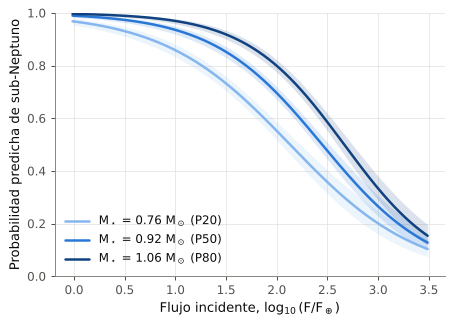

In [12]:
def rejilla_M2(log_flujo, masa):
    r = pd.DataFrame({"log_insol_calculada": log_flujo, "st_mass": masa, "st_met": z["st_met"].median()})
    r["logF_c"] = r["log_insol_calculada"] - z["log_insol_calculada"].mean()
    r["Mstar_c"] = r["st_mass"] - z["st_mass"].mean()
    r["FeH_c"] = r["st_met"] - z["st_met"].mean()
    r["logF_c_x_Mstar_c"] = r["logF_c"] * r["Mstar_c"]
    return pd.concat([r, prediccion_logit(M2, matriz(r, PRED_M2))], axis=1)

flujos = np.linspace(z["log_insol_calculada"].quantile(0.01), z["log_insol_calculada"].quantile(0.99), 200)
curvas = pd.concat([rejilla_M2(flujos, masa).assign(percentil_st_mass=f"P{int(q * 100)}")
                    for q, masa in percentiles_M.items()], ignore_index=True)
curvas.to_csv(DATOS_PROCESADOS / "Z_probabilidad_sub_neptuno_vs_logF.csv", index=False)

def dibujar_curvas_sub_neptuno(ax, curvas):
    for (percentil, d), color in zip(curvas.groupby("percentil_st_mass", sort=False), RAMPA_ORDINAL):
        ax.fill_between(d["log_insol_calculada"], d["IC95_inf"], d["IC95_sup"], color=color, alpha=0.15, linewidth=0)
        ax.plot(d["log_insol_calculada"], d["probabilidad"], color=color,
                label=rf"$M_\star$ = {d['st_mass'].iloc[0]:.2f} $M_\odot$ ({percentil})")
    ax.set_xlabel(EJE["logF"])
    ax.set_ylabel("Probabilidad predicha de sub-Neptuno")
    ax.set_ylim(0, 1)
    ax.legend(loc="lower left")

fig, ax = plt.subplots(figsize=(5.6, 3.8))
dibujar_curvas_sub_neptuno(ax, curvas)
guardar_figura(fig, "Z-F3", "probabilidad_sub_neptuno_vs_flujo",
               titulo=("Probabilidad predicha de que un planeta de 1-4 R_Tierra sea sub-Neptuno en función del flujo incidente, "
                       "para tres masas estelares (percentiles 20, 50 y 80). Modelo M2 con la metalicidad fija en la mediana; "
                       "las bandas son intervalos de confianza al 95 %."),
               seccion="6.2.2")
plt.show()

In [13]:
percentiles_F = z["log_insol_calculada"].quantile([0.2, 0.5, 0.8])
representativas = pd.concat([
    rejilla_M2(np.array([flujo]), masa).assign(percentil_logF=f"P{int(qF * 100)}", percentil_st_mass=f"P{int(qM * 100)}")
    for qF, flujo in percentiles_F.items() for qM, masa in percentiles_M.items()], ignore_index=True)
tabla_representativas = guardar_tabla(
    representativas[["percentil_logF", "log_insol_calculada", "percentil_st_mass", "st_mass",
                     "probabilidad", "IC95_inf", "IC95_sup"]],
    "Z-T9", "probabilidades_predichas_representativas",
    titulo="Probabilidad predicha de sub-Neptuno en los percentiles 20, 50 y 80 del flujo incidente y de la masa estelar (modelo M2).",
    seccion="6.2.2", destino="anexo",
    encabezados={"percentil_logF": r"Percentil $\log F$", "percentil_st_mass": r"Percentil $M_\star$",
                 "st_mass": r"$M_\star$", "probabilidad": "Probabilidad"})
tabla_representativas

Tabla Z-T9 guardada: tablas/Z-T9_probabilidades_predichas_representativas.csv


,percentil_logF,log_insol_calculada,percentil_st_mass,st_mass,probabilidad,IC95_inf,IC95_sup
0,P20,1.198,P20,0.76,0.8153,0.7885,0.8395
1,P20,1.198,P50,0.92,0.9095,0.8901,0.9257
2,P20,1.198,P80,1.0632,0.9545,0.9406,0.9653
3,P50,1.8501,P20,0.76,0.6099,0.5782,0.6407
4,P50,1.8501,P50,0.92,0.7508,0.7268,0.7734
5,P50,1.8501,P80,1.0632,0.8443,0.821,0.865
6,P80,2.4364,P20,0.76,0.3806,0.338,0.4252
7,P80,2.4364,P50,0.92,0.5051,0.4742,0.5359
8,P80,2.4364,P80,1.0632,0.6164,0.5837,0.648


## 4. Verificaciones de robuste

Se repite la comparación M1 → M2 cambiando la muestra o la definición de la respuesta:

1. muestra principal (tránsito, clasificación conservadora);
2. todos los métodos de descubrimiento (incluye planetas cuyo radio es una estimación del archivo);
3. solo planetas descubiertos por Kepler;
4. tránsito con un corte único en $1.6\,R_\oplus$, sin excluir el valle (`sub_neptune` = $R_p > 1.6$).

In [14]:
pequenos["sub_neptune"] = (pequenos["pl_rade"] > R_VALLE_MIN).astype(float)

def comparar_M1_M2(nombre, muestra, respuesta=RESPUESTA):
    m = muestra_zoom(pequenos, muestra, respuesta)
    m1 = ajustar_logit(m[respuesta], matriz(m, PRED_M1), m["hostname"], "M1")
    m2 = ajustar_logit(m[respuesta], matriz(m, PRED_M2), m["hostname"], "M2")
    c = m2.coeficientes(solo=["logF_c_x_Mstar_c"]).iloc[0]
    return {"variante": nombre, "N_planetas": len(m), "N_estrellas": m["hostname"].nunique(),
            "coef_interaccion": c["coeficiente"], "IC95_inf": c["IC95_inf"], "IC95_sup": c["IC95_sup"],
            "valor_p": c["valor_p"], "delta_AIC": m2.aic - m1.aic, "delta_BIC": m2.bic - m1.bic,
            "delta_pseudo_R2": m2.pseudo_r2 - m1.pseudo_r2}

robustez = pd.DataFrame([
    comparar_M1_M2("Tránsito (principal)", "transito"),
    comparar_M1_M2("Todos los métodos", "completa"),
    comparar_M1_M2("Kepler", "kepler"),
    comparar_M1_M2("Tránsito, corte único en 1.6 R_Tierra", "transito", "sub_neptune"),
])
tabla_robustez = guardar_tabla(
    robustez, "Z-T11", "robustez_de_la_interaccion",
    titulo="Robustez de la interacción entre flujo incidente y masa estelar: coeficiente en M2 y mejora de M2 respecto a M1 en distintas muestras y definiciones.",
    seccion="6.2.3", nota="Errores estándar agrupados por estrella.",
    encabezados={"variante": "Variante", "coef_interaccion": "Coef. interacción"},
    formatos={"delta_AIC": "{:+.1f}", "delta_BIC": "{:+.1f}", "delta_pseudo_R2": "{:+.4f}"})
tabla_robustez

Tabla Z-T11 guardada: tablas/Z-T11_robustez_de_la_interaccion.csv


,variante,N_planetas,N_estrellas,coef_interaccion,IC95_inf,IC95_sup,valor_p,delta_AIC,delta_BIC,delta_pseudo_R2
0,Tránsito (principal),2565,1981,-1.5901,-2.1265,-1.0537,6.24e-09,-40.1941,-34.3443,0.013
1,Todos los métodos,2775,2097,-1.4958,-1.9076,-1.084,1.09e-12,-53.2771,-47.3487,0.0158
2,Kepler,1876,1455,-2.0175,-2.8696,-1.1654,3.47e-06,-28.6107,-23.0738,0.0126
3,"Tránsito, corte único en 1.6 R_Tierra",3116,2293,-1.2809,-1.7354,-0.8264,3.33e-08,-33.0352,-26.9909,0.0095


### Control orbital: período o flujo incidente

El flujo incidente resume período, masa, radio y temperatura de la estrella. Se compara M1 con el mismo modelo usando el período orbital en lugar del flujo.

In [15]:
z["logP_c"] = np.log10(z["pl_orbper"]) - np.log10(z["pl_orbper"]).mean()
con_periodo = ajustar_logit(y, matriz(z, ["logP_c", "Mstar_c", "FeH_c"]), grupos, "M1 con período")
control = comparar_modelos({"M1 con período": con_periodo, "M1 con flujo": M1},
                                   {"M1 con período": "logP_c + Mstar_c + FeH_c", "M1 con flujo": formulas["M1"]},
                                   deltas=["AIC", "pseudo_R2"])
tabla_control = guardar_tabla(
    control.rename(columns={"N": "N_planetas"}), "Z-T12", "control_orbital_periodo_o_flujo",
    titulo="Comparación del modelo M1 con el período orbital o con el flujo incidente como control orbital.",
    seccion="6.2.3", destino="anexo", formatos={"delta_AIC": "{:+.1f}"})
tabla_control

Tabla Z-T12 guardada: tablas/Z-T12_control_orbital_periodo_o_flujo.csv


,modelo,predictores,N_planetas,pseudo_R2,AIC,BIC,log_loss,brier,delta_AIC,delta_pseudo_R2
0,M1 con período,logP_c + Mstar_c + FeH_c,2565,0.1902,2644.26,2667.66,0.5139,0.1707,0,0
1,M1 con flujo,logF_c + Mstar_c + FeH_c,2565,0.1785,2682.57,2705.97,0.5214,0.1737,38.305,-0.0118


### Colinealidad entre predictores

La temperatura efectiva y el radio estelar no entran en los modelos porque están fuertemente correlacionados con la masa estelar.

In [16]:
z["logP"] = np.log10(z["pl_orbper"])
variables_corr = ["log_insol_calculada", "st_mass", "st_teff", "st_rad", "logP", "st_met"]
correlaciones = z[variables_corr].corr(method="spearman").reset_index().rename(columns={"index": "variable"})
tabla_vif = vif(z, PRED_M2)
texto_vif = "; ".join(f"{f.predictor}: {f.VIF:.2f}" for f in tabla_vif.itertuples())
tabla_correlaciones = guardar_tabla(
    correlaciones, "Z-T13", "correlaciones_entre_predictores",
    titulo="Correlaciones de Spearman entre el flujo incidente, el período y las propiedades estelares en la muestra principal.",
    seccion="6.2.3", destino="anexo", decimales=3,
    nota=f"Factores de inflación de la varianza de los predictores de M2: {texto_vif}.",
    encabezados={v: SIMBOLO.get(v, v) for v in variables_corr})
display(tabla_vif)
tabla_correlaciones

Tabla Z-T13 guardada: tablas/Z-T13_correlaciones_entre_predictores.csv


,predictor,VIF
0,logF_c,1.254
1,Mstar_c,1.39292
2,FeH_c,1.10077
3,logF_c_x_Mstar_c,1.06063


,variable,log_insol_calculada,st_mass,st_teff,st_rad,logP,st_met
0,log_insol_calculada,1,0.432,0.403,0.437,-0.745,0.185
1,st_mass,0.432,1,0.924,0.936,0.163,0.331
2,st_teff,0.403,0.924,1,0.917,0.199,0.126
3,st_rad,0.437,0.936,0.917,1,0.186,0.263
4,logP,-0.745,0.163,0.199,0.186,1,-0.063
5,st_met,0.185,0.331,0.126,0.263,-0.063,1


## Lectura de los resultados

- La fracción de sub-Neptunos disminuye con el flujo incidente y aumenta con la masa estelar (tabla Z-T2, figura Z-F2).
- Añadir $M_\star$ y [Fe/H] mejora mucho el modelo que solo usa el flujo; la interacción flujo × masa estelar lo mejora de nuevo, y la mejora se mantiene en validación cruzada (tablas Z-T3 a Z-T5).
- El coeficiente de la interacción es negativo: el efecto del flujo es más fuerte alrededor de estrellas más masivas (tabla Z-T8, figura Z-F3).
- La interacción conserva signo y magnitud en todas las variantes de robustez (tabla Z-T11).
- Con el período orbital en lugar del flujo, el modelo M1 ajusta algo mejor (tabla Z-T12). El flujo incidente se usa por su interpretación física (pérdida atmosférica), no porque ajuste mejor; conviene decirlo así en el texto.